In [2]:
!pip install matplotlib

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("air_quality_health.csv")

In [4]:
def aqi_category(aqi):
    if aqi <= 50:
        return "Good"
    elif aqi <= 100:
        return "Moderate"
    elif aqi <= 200:
        return "Unhealthy"
    elif aqi <= 300:
        return "Very Unhealthy"
    else:
        return "Hazardous"


df['AQI_Category'] = df['AQI'].apply(aqi_category)


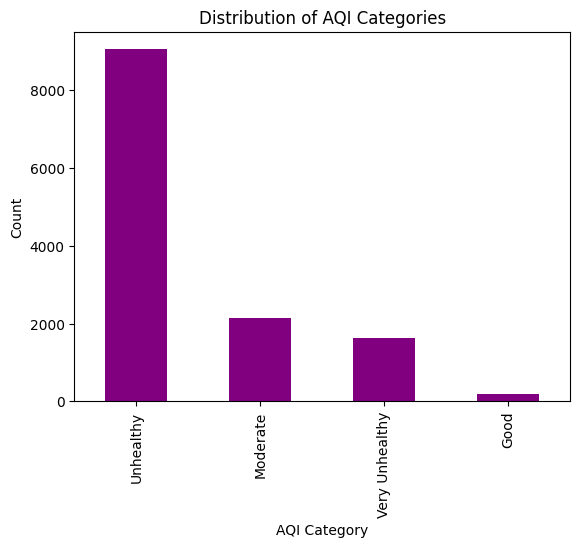

In [5]:
import matplotlib.pyplot as plt

plt.figure()
df['AQI_Category'].value_counts().plot(kind='bar',color='purple')
plt.xlabel("AQI Category")
plt.ylabel("Count")
plt.title("Distribution of AQI Categories")
plt.show()

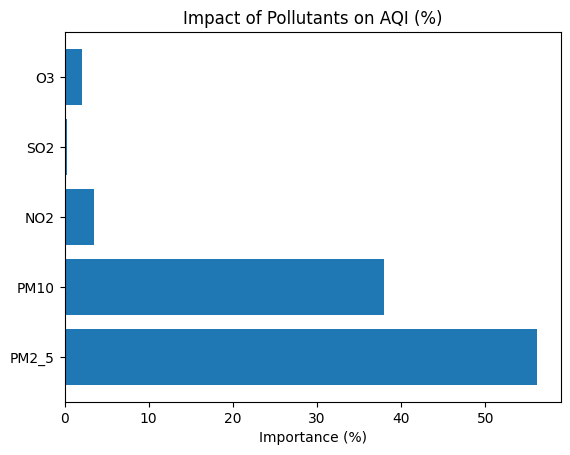

In [4]:
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt

X = df[['PM2_5', 'PM10', 'NO2', 'SO2', 'O3']]
y = df['AQI']

pollutant_model = RandomForestRegressor(random_state=42)
pollutant_model.fit(X, y)

importance = pollutant_model.feature_importances_
importance_percent = importance * 100

plt.figure()
plt.barh(X.columns, importance_percent)
plt.xlabel("Importance (%)")
plt.title("Impact of Pollutants on AQI (%)")
plt.show()


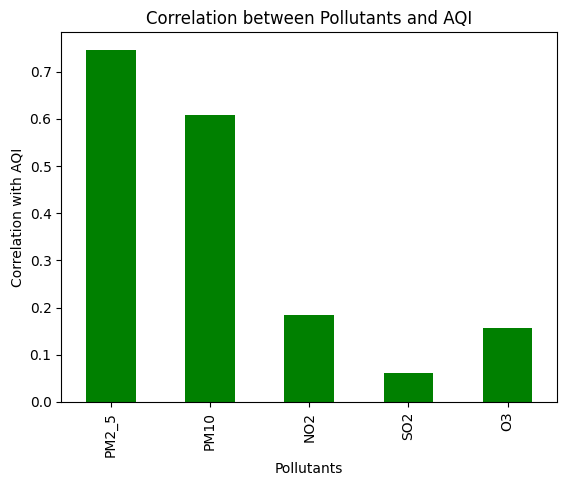

In [5]:
pollutants = ['PM2_5', 'PM10', 'NO2', 'SO2', 'O3']

# Correlation with AQI
correlation = df[pollutants + ['AQI']].corr()['AQI'].drop('AQI')

plt.figure()
correlation.plot(kind='bar',color='green')
plt.xlabel("Pollutants")
plt.ylabel("Correlation with AQI")
plt.title("Correlation between Pollutants and AQI")
plt.show()

In [6]:
!pip install seaborn

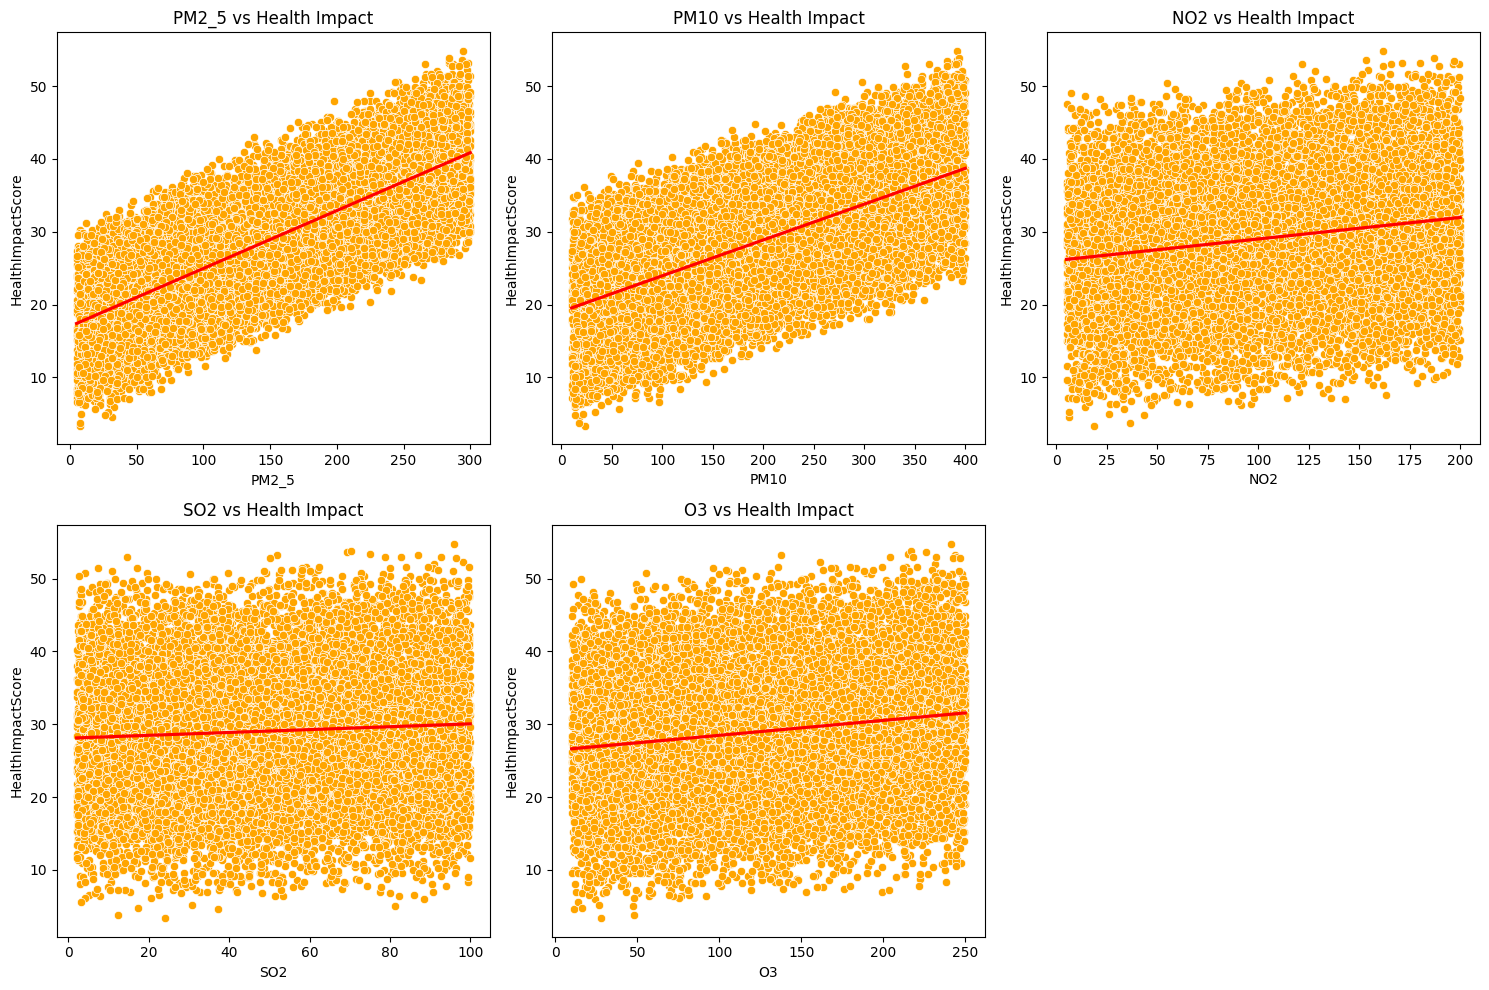

In [7]:
pollutants = ['PM2_5', 'PM10', 'NO2', 'SO2', 'O3']
import seaborn as sns
plt.figure(figsize=(15,10))
for i, pollutant in enumerate(pollutants, 1):
    plt.subplot(2,3,i)
    sns.scatterplot(x=df[pollutant], y=df['HealthImpactScore'],color='orange')
    sns.regplot(x=df[pollutant], y=df['HealthImpactScore'], scatter=False, color='red')
    plt.title(f'{pollutant} vs Health Impact')
plt.tight_layout()
plt.show()

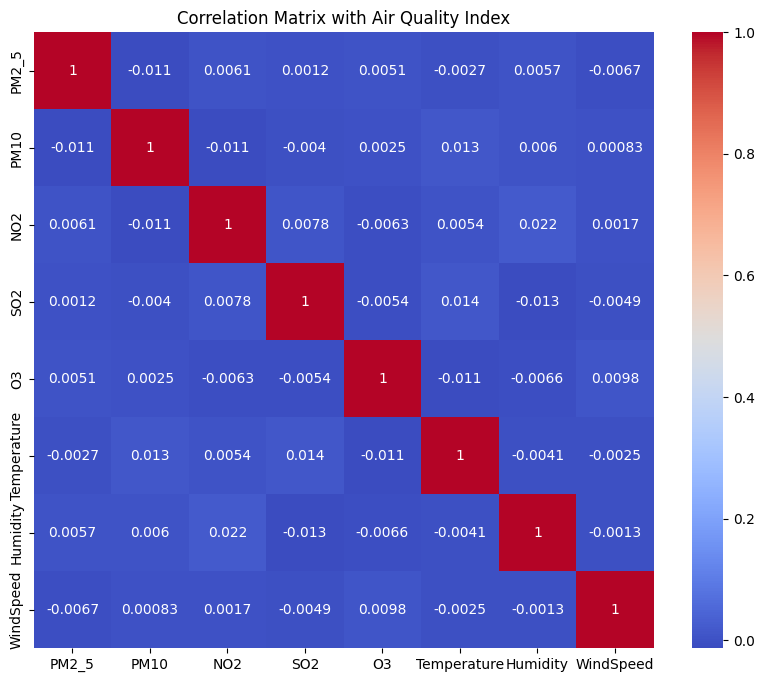

In [8]:

features = ['PM2_5', 'PM10', 'NO2', 'SO2', 'O3', 'Temperature', 'Humidity', 'WindSpeed']

plt.figure(figsize=(10,8))
sns.heatmap(df[features].corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Matrix with Air Quality Index")
plt.show()

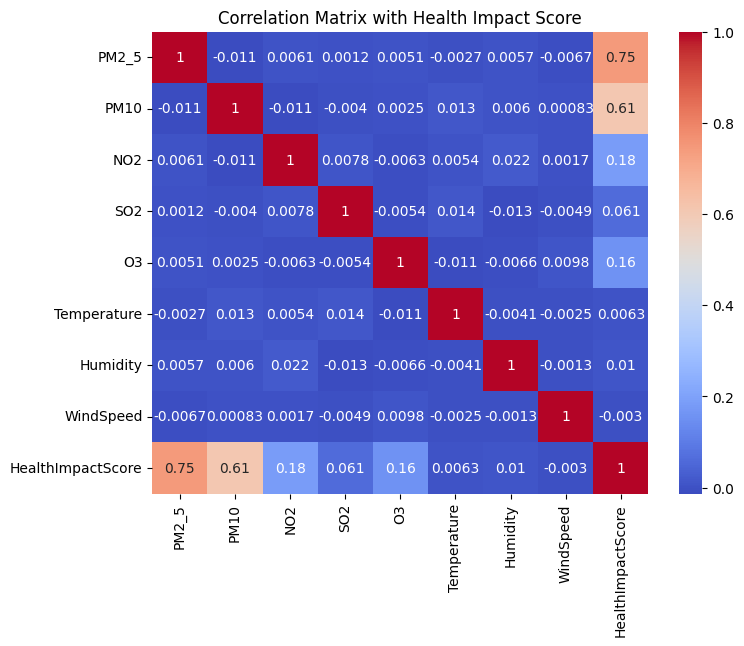

In [9]:
plt.figure(figsize=(8,6))
corr = df[['PM2_5', 'PM10', 'NO2', 'SO2', 'O3', 'Temperature', 'Humidity', 'WindSpeed', 'HealthImpactScore']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix with Health Impact Score')
plt.show()